# «Анализ данных об оптовых продажах аудиотехники»

«Карпов Саунд» сотрудничает с крупными розничными сетями и специализированными магазинами аудиотехники в России. Клиенты компании регулярно оставляют заявки на закупку товаров в CRM системе, менеджеры связываются с клиентами, обсуждают детали, после чего заказы либо подтверждаются менеджерами, либо по разным причинам отменяются. 

В «Карпов Саунд» трепетно относятся к хранению информации о своих товарах, клиентах и заказах, однако в самый неподходящий момент хранилище данных компании оказалось временно недоступно из-за плановых работ по его оптимизации. Поэтому в рамках этого проекта все данные будут представлены не в самом удобном для анализа виде — в формате резервной выгрузки, разложенной по разным папкам на сервере компании.

Вам необходимо собрать данные из разрозненных источников, проанализировать их и сделать выводы, которые помогут руководству компании принять верные тактические решения.

**В ходе работы над проектом встретятся следующие таблицы:**  

1) orders (данные о заказах):  
- order_id — номер заказа  
- product_id — идентификатор товара  
- quantity — количество этого товара в заказе

2) order_status (данные о статусах заказов и клиентах):
- order_id — номер заказа  
- client_id — идентификатор клиента  
- status — статус заказа

3) products (данные о товарах):
- id — идентификатор товара  
- name — имя товара (сначала указан бренд, через запятую модель товара)  
- price — цена единицы товара, в долларах

Каждый заказ имеет статус или подтвержденного (`confirmed`), или отмененного (`canceled`). В одном заказе может быть несколько разных товаров. Если заказ был отменен, а потом создан такой же (тем же клиентом, с теми же товарами, у того же менеджера), в базе останется запись о двух заказах с разными номерами и статусами, поскольку система не позволяет создать заказ с тем же номером.

Сначала вам нужно собрать и предобработать три типа датасетов: `orders.csv`, `order_status.csv`, `products.csv`.

На схеме показано, как связаны таблицы между собой:

![](https://storage.yandexcloud.net/klms-public/production/learning-content/457/4167/37264/104636/497986/er_white.png)

Данные находятся в папке `data` из директории `shared` (`shared` -> `homeworks` -> `python_ds_miniprojects` -> `final_project`). Внутри папки `data` находятся 2 другие папки: `orders` и `products`.

В папке `orders` папки с датами, в которые сделаны записи. В этих папках — папки с именами менеджеров по продажам. Эти папки содержат файлы `orders.csv` и `order_status.csv` (в каждой папке по одной паре файлов). Пример структуры: `data` -> `orders` -> `2024-03-01` -> `Алексей Саксофонов` -> `orders.csv` и `order_status.csv`.

В папке `products` папки с категориями товаров. В этих папках файлы `products.csv` (в каждой папке по одному файлу). Пример структуры: `data` -> `products` -> `AV-процессор` -> `products.csv`.

Кроме того у вас есть файл `usd_rate.txt` с курсом доллара США на каждый день анализируемого периода (данные в формате `дата,курс,валюта`). Он потребуется в середине проекта.

В финальном проекте модуля вы можете пользоваться подсказками в ноутбуке (они менее подробные, чем были в предыдущих уроках), обращаться за помощью к экспертам в Discord и смотреть разборы в LMS (за просмотр разбора снимается половина баллов за задание).

### Соберем датасет с заказами по папкам

In [1]:
import pandas as pd
import os


The history saving thread hit an unexpected error (DatabaseError('database disk image is malformed')).History will not be written to the database.


In [2]:
student_login = 'anna-alekseeva-xqs4656'


In [3]:
target_files = os.listdir(f'/mnt/HC_Volume_18315164/home-jupyter/jupyter-{student_login}/shared/homeworks/python_ds_miniprojects/final_project/data')
target_files


['products', 'orders']

In [4]:
data_path = f'/mnt/HC_Volume_18315164/home-jupyter/jupyter-{student_login}/shared/homeworks/python_ds_miniprojects/final_project/data'

In [5]:
data_files = []

for path, dirs, files in os.walk(data_path):
    for file in files:
        if file.endswith('.csv'):
            full_path = os.path.join(path, file)
            data_files.append(full_path)

print(f"Найдено файлов: {len(data_files)}")
for p in data_files[:5]:
    print(p)
    

Найдено файлов: 382
/mnt/HC_Volume_18315164/home-jupyter/jupyter-anna-alekseeva-xqs4656/shared/homeworks/python_ds_miniprojects/final_project/data/products/Активные колонки/products.csv
/mnt/HC_Volume_18315164/home-jupyter/jupyter-anna-alekseeva-xqs4656/shared/homeworks/python_ds_miniprojects/final_project/data/products/Сабвуфер/products.csv
/mnt/HC_Volume_18315164/home-jupyter/jupyter-anna-alekseeva-xqs4656/shared/homeworks/python_ds_miniprojects/final_project/data/products/Портативная акустика/products.csv
/mnt/HC_Volume_18315164/home-jupyter/jupyter-anna-alekseeva-xqs4656/shared/homeworks/python_ds_miniprojects/final_project/data/products/AV-процессор/products.csv
/mnt/HC_Volume_18315164/home-jupyter/jupyter-anna-alekseeva-xqs4656/shared/homeworks/python_ds_miniprojects/final_project/data/products/Динамический микрофон/products.csv


In [6]:
orders_df_list = []
order_status_df_list = []
products_df_list = []


In [7]:
for path, dirs, files in os.walk(data_path):
    for file in files:
        full_path = os.path.join(path, file)
        parts = path.split('/')
        
        if file.endswith('order_status.csv'):
            df = pd.read_csv(full_path)
            order_status_df_list.append(df)
            
        elif file.endswith('orders.csv'):
            df = pd.read_csv(full_path)
            df['manager'] = parts[-1]
            df['date'] = parts[-2]
            orders_df_list.append(df)
            
        elif file.endswith('products.csv'):
            df = pd.read_csv(full_path)
            df['category'] = parts[-2]
            products_df_list.append(df)

In [8]:
df_orders = pd.concat(orders_df_list, ignore_index=True)
df_order_status = pd.concat(order_status_df_list, ignore_index=True)
df_products = pd.concat(products_df_list, ignore_index=True)

In [9]:
df_orders = df_orders.sort_values(['order_id', 'product_id'])
df_order_status = df_order_status.sort_values('order_id')
df_products = df_products.sort_values('id')

In [10]:
df_orders['quantity'].sum()


85062

In [11]:
df_order_status['client_id'].sum()


18347

In [12]:
df_products['price'].sum()

839000.25

### Посмотрим на общую динамику заказов и определим дни, которые выбиваются из общей картины

In [13]:
df_orders.reset_index(drop=True)

,order_id,product_id,quantity,manager,date
0,ABID-18767701,72,30,Маргарита Камертонова,2024-03-11
1,ABID-18767701,509,40,Маргарита Камертонова,2024-03-11
2,ABID-18767701,555,26,Маргарита Камертонова,2024-03-11
3,ABID-18767701,557,30,Маргарита Камертонова,2024-03-11
4,ABID-18767701,569,28,Маргарита Камертонова,2024-03-11
...,...,...,...,...,...
4598,ZVTW-19610380,1171,28,Ксения Балалайкина,2024-03-22
4599,ZVTW-19610380,1308,4,Ксения Балалайкина,2024-03-22
4600,ZVTW-19610380,1476,4,Ксения Балалайкина,2024-03-22
4601,ZVTW-19610380,1517,11,Ксения Балалайкина,2024-03-22


In [14]:
df_orders['date'] = pd.to_datetime(df_orders['date'])

In [15]:
df_orders.head(5)


,order_id,product_id,quantity,manager,date
4370,ABID-18767701,72,30,Маргарита Камертонова,2024-03-11
4367,ABID-18767701,509,40,Маргарита Камертонова,2024-03-11
4378,ABID-18767701,555,26,Маргарита Камертонова,2024-03-11
4372,ABID-18767701,557,30,Маргарита Камертонова,2024-03-11
4376,ABID-18767701,569,28,Маргарита Камертонова,2024-03-11


In [16]:
df_orders_sum_of_days = df_orders.groupby('date', as_index=False).agg({'order_id': 'nunique'}).sort_values('order_id', ascending=False)
df_orders_sum_of_days

,date,order_id
13,2024-03-14,34
12,2024-03-13,24
0,2024-03-01,22
28,2024-03-29,19
4,2024-03-05,18
26,2024-03-27,18
14,2024-03-15,17
25,2024-03-26,17
21,2024-03-22,16
11,2024-03-12,15


In [17]:
import seaborn as sns
import matplotlib.pyplot as plt


In [18]:
df_daily = df_orders.groupby('date')['order_id'].nunique().reset_index()

In [19]:
df_daily['date'] = pd.to_datetime(df_daily['date'])
df_daily['day_of_week'] = df_daily['date'].dt.day_name()

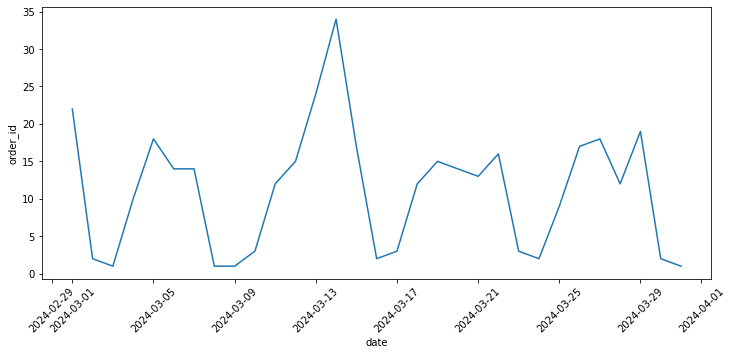

In [20]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=df_daily, x='date', y='order_id')
plt.xticks(rotation=45)  # поворачиваем подписи дат для удобства
plt.show()

In [21]:
df_daily['date'] = pd.to_datetime(df_daily['date'])
df_daily['day_of_week'] = df_daily['date'].dt.day_name()

In [22]:
df_daily.max()

date           2024-03-31 00:00:00
order_id                        34
day_of_week              Wednesday
dtype: object

In [23]:
df_daily.groupby('day_of_week')['order_id'].mean()

day_of_week
Friday       15.00
Monday       10.75
Saturday      2.00
Sunday        2.00
Thursday     18.25
Tuesday      16.25
Wednesday    17.50
Name: order_id, dtype: float64

In [24]:
df_daily

,date,order_id,day_of_week
0,2024-03-01,22,Friday
1,2024-03-02,2,Saturday
2,2024-03-03,1,Sunday
3,2024-03-04,10,Monday
4,2024-03-05,18,Tuesday
5,2024-03-06,14,Wednesday
6,2024-03-07,14,Thursday
7,2024-03-08,1,Friday
8,2024-03-09,1,Saturday
9,2024-03-10,3,Sunday


In [25]:
df_daily.day_of_week

0        Friday
1      Saturday
2        Sunday
3        Monday
4       Tuesday
5     Wednesday
6      Thursday
7        Friday
8      Saturday
9        Sunday
10       Monday
11      Tuesday
12    Wednesday
13     Thursday
14       Friday
15     Saturday
16       Sunday
17       Monday
18      Tuesday
19    Wednesday
20     Thursday
21       Friday
22     Saturday
23       Sunday
24       Monday
25      Tuesday
26    Wednesday
27     Thursday
28       Friday
29     Saturday
30       Sunday
Name: day_of_week, dtype: object

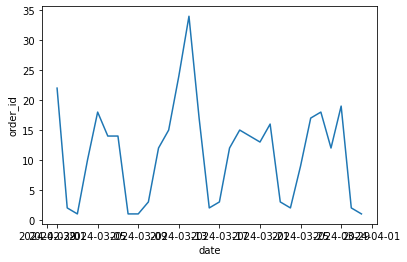

In [26]:
sns.lineplot(x='date', y='order_id', data=df_orders_sum_of_days)

**Кажется, в данных помимо дня с наибольшим числом заказов есть еще один день, который выбивается из общей картины.** 

К вам пришел радостный руководитель отдела продаж и попросил выяснить причину, почему заказы в один из дней резко подскочили, чтобы и дальше увеличивать продажи.

Возможно, в день с наибольшим числом заказов (который вы определили на третьем шаге) отдел маркетинга запустил какую-то акцию? Или менеджеры стали активнее предлагать компаниям оформить заказ? Нужно подробнее изучить этот день. Начнем со статусов заказа.

**Добавьте к данным о заказах информацию об их статусах. Общий датафрейм назовите `orders_status`. Сохраните получившийся датафрейм в csv файл `orders_status.csv` (при сохранении используйте параметр `index=False`) и отправьте этот csv файл на проверку в LMS.**

In [27]:
orders_status = pd.merge(df_orders, df_order_status, on='order_id')

In [28]:
orders_status.head(10)

,order_id,product_id,quantity,manager,date,client_id,status
0,ABID-18767701,72,30,Маргарита Камертонова,2024-03-11,44,confirmed
1,ABID-18767701,509,40,Маргарита Камертонова,2024-03-11,44,confirmed
2,ABID-18767701,555,26,Маргарита Камертонова,2024-03-11,44,confirmed
3,ABID-18767701,557,30,Маргарита Камертонова,2024-03-11,44,confirmed
4,ABID-18767701,569,28,Маргарита Камертонова,2024-03-11,44,confirmed
5,ABID-18767701,634,20,Маргарита Камертонова,2024-03-11,44,confirmed
6,ABID-18767701,644,26,Маргарита Камертонова,2024-03-11,44,confirmed
7,ABID-18767701,673,40,Маргарита Камертонова,2024-03-11,44,confirmed
8,ABID-18767701,766,22,Маргарита Камертонова,2024-03-11,44,confirmed
9,ABID-18767701,780,20,Маргарита Камертонова,2024-03-11,44,confirmed


In [29]:
orders_status.to_csv('orders_status.csv', index=False)

In [30]:
orders_status.client_id.sum()

251232

Посмотрите на количество и соотношение подтвержденных и отмененных заказов. **В ответе укажите долю отмененных заказов.** Ответ округлите до двух знаков после точки.

In [31]:
orders_status_1 = orders_status.drop_duplicates(subset='order_id')['status'].value_counts(normalize=True)
orders_status_1


confirmed    0.893064
canceled     0.106936
Name: status, dtype: float64

**Посчитайте количество подтвержденных и отмененных заказов на каждую дату.** Определите, в какой день не было ни одного подтвержденного заказа. Для этого сделайте сводную таблицу, где в строках будут даты, в колонках — стутасы заказов, а значения — число заказов с этим статусом в определенную дату. Пропуски заполните нулями.  

**В ответ укажите день, когда не было ни одного подтвержденного заказа.** Дату укажите в том формате, в котором она представлена в данных (гггг-мм-дд).

In [32]:
orders_status_2 = orders_status.groupby(['date','status'])['order_id'].nunique().unstack().fillna(0)
orders_status_2

status,canceled,confirmed
date,,
2024-03-01,2.0,20.0
2024-03-02,0.0,2.0
2024-03-03,0.0,1.0
2024-03-04,0.0,10.0
2024-03-05,0.0,18.0
2024-03-06,1.0,13.0
2024-03-07,1.0,13.0
2024-03-08,0.0,1.0
2024-03-09,1.0,0.0


**Постройте график с заказами по дням в разбивке по статусу заказа.** Посмотрим подробнее на день с наибольшим числом заказов (вместе и подтвержденных, и отменных), который мы определили ранее, и на день, предшествующий ему. Какой вывод можно сделать? Выберите один или несколько вариантов:

- В день с наибольшим числом заказов было очень много отмен  
- В день с наибольшим числом заказов было много успешно оформленных заказов  
- В день, предшествующий дню с наибольшим числом заказов, было много отмен  
- В день, предшествующий дню с наибольшим числом заказов, было много успешно оформленных заказов  
- В день, предшествующий дню с наибольшим числом заказов, не было ни одного успешно оформленного заказа  
- В день, предшествующий дню с наибольшим числом заказов, не было ни одного отмененного заказа

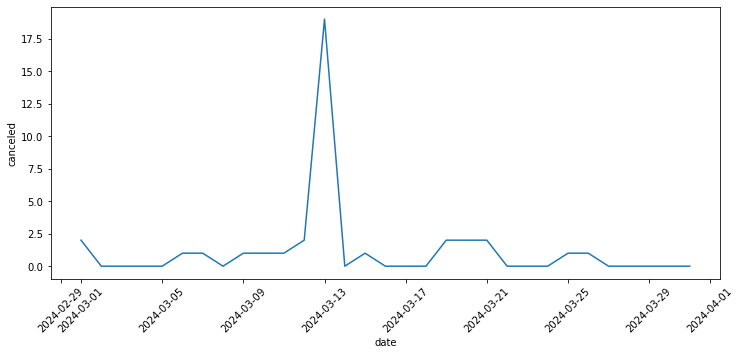

In [33]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=orders_status_2, x='date', y='canceled')
plt.xticks(rotation=45)  # поворачиваем подписи дат для удобства
plt.show()

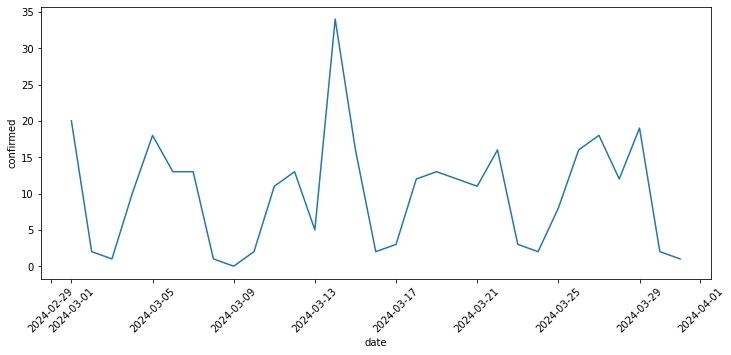

In [34]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=orders_status_2, x='date', y='confirmed')
plt.xticks(rotation=45)  # поворачиваем подписи дат для удобства
plt.show()

Рассмотрим эти два дня отдельно (день с наибольшим числом заказов, который мы определили ранее, и день, предшествующий ему). Проанализируйте заказы за эти дни и ответьте, какую из этих гипотез можно назвать наиболее правдоподобной.

- Так сложилось, что один день оказался крайне неудачным для отдела продаж, все клиенты отменили свои заказы. А на следующий день отдел продаж пытался компенсировать отсутствие продаж в предыдущий и перевыполнил дневной план. Почти все заказы не повторяют вчерашние  
- Произошел сбой в работе CRM системы, который не позволил клиентам подтвердить заказ. В результате все созданные в первый день заказы автоматически отменились, поэтому клиентам пришлось оформлять их повторно на следующий день. Почти половина заказов повторяет вчерашние

Как можно определить, что заказ повторяет вчерашний? У заказов будут совпадать сразу несколько параметров: клиент, менеджер, количество уникальных товаров в заказе и общее число товаров в штуках. Но номера заказов будут разными.

### Посчитаем ключевые метрики, посмотрим на их динамику и составим небольшой отчет

**У вас есть данные за целый месяц, поэтому пора посчитать ключевые метрики этого месяца.** Но вот незадача - в ваших данных цена единицы товара указана в долларах США, потому что закупаете их в долларах, но продаете товары за российские рубли (по тому курсу, который установил Центробанк на дату продажи), а значит и метрики требуется посчитать в рублях. Хорошо, что у вас есть текстовый файл с курсом доллара США на каждую дату. **Откройте файл `usd_rate.txt`, соберите из него датафрейм с 2 колонками: `date` и `currency_rate`. Посчитайте среднее значение курса доллара за месяц.** Результат округлите до двух знаков после точки.

In [35]:
with open('usd_rate.txt', 'r', encoding='utf-8') as file:
    currency = file.readlines()

In [36]:
usd_rate = pd.read_csv('usd_rate.txt', header=None, names=['date', 'currency_rate', 'currency'])
usd_rate

,date,currency_rate,currency
0,2024-03-01,90.8423,Доллар США
1,2024-03-02,91.3336,Доллар США
2,2024-03-03,91.3336,Доллар США
3,2024-03-04,91.3336,Доллар США
4,2024-03-05,91.3534,Доллар США
5,2024-03-06,91.1604,Доллар США
6,2024-03-07,90.3412,Доллар США
7,2024-03-08,90.7493,Доллар США
8,2024-03-09,90.7493,Доллар США
9,2024-03-10,90.7493,Доллар США


In [37]:
usd_rate = usd_rate[['date', 'currency_rate']]
usd_rate

,date,currency_rate
0,2024-03-01,90.8423
1,2024-03-02,91.3336
2,2024-03-03,91.3336
3,2024-03-04,91.3336
4,2024-03-05,91.3534
5,2024-03-06,91.1604
6,2024-03-07,90.3412
7,2024-03-08,90.7493
8,2024-03-09,90.7493
9,2024-03-10,90.7493


In [38]:
usd_rate.dtypes

date              object
currency_rate    float64
dtype: object

In [39]:
usd_rate['date'] = pd.to_datetime(usd_rate['date'])

/tmp/ipykernel_166/2513218024.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  usd_rate['date'] = pd.to_datetime(usd_rate['date'])


In [40]:
usd_rate.currency_rate.mean()

91.69706451612903

**Работу с ключевыми метриками начните с подсчета общей выручки.** Данные по товарам в подтвержденных заказах у вас есть в датафрейме `orders_status`, а стоимость одной единицы товара можно взять из датафрейма `df_products`. Объедините эти датафреймы в общий `df_full`, добавьте к ним информацию по курсу доллара на каждую дату. Создайте колонку с выручкой для каждого товара в заказах и посчитайте, **чему равна общая выручка в рублях?** Учитывайте только подтвержденные заказы. Результат округлите до двух знаков после точки.

In [41]:
df_full = pd.merge(orders_status, df_products, left_on='product_id', right_on='id', how='left')

In [42]:
df_full = pd.merge(df_full, usd_rate, on='date', how='left')

In [43]:
df_full['price_rub'] = df_full['price'] * df_full['currency_rate']

In [44]:
df_full['revenue'] = df_full['price_rub'] * df_full['quantity']

In [45]:
df_confirmed = df_full[df_full['status'] == 'confirmed']
df_confirmed

,order_id,product_id,quantity,manager,date,client_id,status,id,name,price,category,currency_rate,price_rub,revenue
0,ABID-18767701,72,30,Маргарита Камертонова,2024-03-11,44,confirmed,72,"Beyerdynamic, DT 990 PRO",158.91,products,90.7493,14420.971263,4.326291e+05
1,ABID-18767701,509,40,Маргарита Камертонова,2024-03-11,44,confirmed,509,"Heco, Stay 300",43.95,products,90.7493,3988.431735,1.595373e+05
2,ABID-18767701,555,26,Маргарита Камертонова,2024-03-11,44,confirmed,555,"JBL, Charge 4",159.13,products,90.7493,14440.936109,3.754643e+05
3,ABID-18767701,557,30,Маргарита Камертонова,2024-03-11,44,confirmed,557,"JBL, Xtreme 2",308.70,products,90.7493,28014.308910,8.404293e+05
4,ABID-18767701,569,28,Маргарита Камертонова,2024-03-11,44,confirmed,569,"JBL, Live 650BTNC",178.47,products,90.7493,16196.027571,4.534888e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4598,ZVTW-19610380,1171,28,Ксения Балалайкина,2024-03-22,44,confirmed,1171,"Pioneer, FAYOLA FS-W40",405.50,products,91.9499,37285.684450,1.043999e+06
4599,ZVTW-19610380,1308,4,Ксения Балалайкина,2024-03-22,44,confirmed,1308,"SMSL, SA-36A Pro",59.71,products,91.9499,5490.328529,2.196131e+04
4600,ZVTW-19610380,1476,4,Ксения Балалайкина,2024-03-22,44,confirmed,1476,"TONOR, PA System Karaoke Machine",98.17,products,91.9499,9026.721683,3.610689e+04
4601,ZVTW-19610380,1517,11,Ксения Балалайкина,2024-03-22,44,confirmed,1517,"Wharfedale, OBSIDIAN 600 Cinema",870.99,products,91.9499,80087.443401,8.809619e+05


In [46]:
df_confirmed.revenue.sum().round(2)

2038231821.56

**Следующая метрика, которую вам нужно посчитать — средний чек в этом месяце (в рублях).** Разделите общую выручку на количество заказов. Результат округлите до двух знаков после точки.

In [47]:
df_confirmed.revenue.sum() / df_confirmed.quantity.sum()



26982.86718691075

In [48]:
df_confirmed_UN = df_confirmed['order_id'].nunique()
df_confirmed_UN

309

In [49]:
df_confirmed.revenue.sum() / 309



6596219.487264932

Ключевые метрики месяца вы посчитали, теперь попробуйте посмотреть на их динамику внутри месяца: посчитайте выручку, средний чек и число заказов — на каждый день. Посмотрите на графики и выберите верные ответы:

- число заказов и выручка каждый день изменяются в одинаковом направлении (если в этот день число заказов выросло, то и выручка выросла; число заказов упало — в этот же день упала и выручка)  
- число заказов и выручка не каждый день изменяются в одинаковом направлении (если в какой-то день число заказов выросло, то выручка может упасть, и наоборот: число заказов упало — в этот же день выручка выросла)  
- средний чек и выручка каждый день изменяются в одинаковом направлении (если в этот день средний чек вырос, то и выручка выросла; средний чек упал — в этот же день упала и выручка)  
- средний чек и выручка не каждый день изменяются в одинаковом направлении (если в какой-то день средний чек вырос, то выручка может упасть, и наоборот: средний чек упал — в этот же день выручка выросла)  
- в день с наибольшим числом заказов и выручка, и средний чек также показывают максимальное значение  
- в день с наибольшим числом заказов выручка и/или средний чек не показывают максимальное значение  
- с течением времени выручка то увеличивается, то уменьшается  
- с течением времени выручка только увеличивается  
- на протяжении всего месяца средний чек то увеличивается, то уменьшается  
- средний чек на протяжении всего месяца имеет одинаковое значение

In [50]:
# Группируем по дате и считаем сразу суммарную выручку и количество уникальных заказов за день
df_report_by_date = df_confirmed.groupby('date').agg(
    daily_revenue=('price_rub', 'sum'),     # укажите ваше название колонки с выручкой
    daily_orders=('order_id', 'nunique')
).reset_index()

# Считаем средний чек на каждый день
df_report_by_date['orders'] = df_report_by_date['daily_revenue'] / df_report_by_date['daily_orders']

# Смотрим на полученную таблицу
df_report_by_date


,date,daily_revenue,daily_orders,orders
0,2024-03-01,1.017928e+07,20,508964.061898
1,2024-03-02,7.397446e+05,2,369872.309916
2,2024-03-03,1.787554e+05,1,178755.381912
3,2024-03-04,4.122937e+06,10,412293.661774
4,2024-03-05,6.613402e+06,18,367411.245099
5,2024-03-06,7.425488e+06,13,571191.361729
6,2024-03-07,5.896333e+06,13,453564.040511
7,2024-03-08,1.265998e+05,1,126599.810965
8,2024-03-10,8.475213e+05,2,423760.662547
9,2024-03-11,5.094736e+06,11,463157.779906


In [51]:
df_report_by_date.sort_values(by='daily_revenue')

,date,daily_revenue,daily_orders,orders
7,2024-03-08,1.265998e+05,1,126599.810965
2,2024-03-03,1.787554e+05,1,178755.381912
29,2024-03-31,6.236478e+05,1,623647.842720
14,2024-03-16,6.366637e+05,2,318331.846750
1,2024-03-02,7.397446e+05,2,369872.309916
8,2024-03-10,8.475213e+05,2,423760.662547
28,2024-03-30,8.642520e+05,2,432126.018060
22,2024-03-24,9.830965e+05,2,491548.241916
15,2024-03-17,1.103279e+06,3,367759.591033
21,2024-03-23,1.715635e+06,3,571878.482412


### Проанализируем интерес клиентов к брендам

К вам снова обратился руководитель отдела продаж. Он хочет разобраться, какие бренды востребованы среди клиентов, а какие — нет. На основе данных о названиях товаров в датафрейме `df_full` создайте новую колонку `brand`, где будет только название бренда. **Посчитайте, сколькими брендами интересовались клиенты** (статус заказа здесь не важен, если запись о бренде попала в данные о заказах, значит клиент заказал или хотел заказать товар этого бренда).

In [52]:
df_full['brand'] = df_full['name'].str.split(',').str[0]
df_full

,order_id,product_id,quantity,manager,date,client_id,status,id,name,price,category,currency_rate,price_rub,revenue,brand
0,ABID-18767701,72,30,Маргарита Камертонова,2024-03-11,44,confirmed,72,"Beyerdynamic, DT 990 PRO",158.91,products,90.7493,14420.971263,4.326291e+05,Beyerdynamic
1,ABID-18767701,509,40,Маргарита Камертонова,2024-03-11,44,confirmed,509,"Heco, Stay 300",43.95,products,90.7493,3988.431735,1.595373e+05,Heco
2,ABID-18767701,555,26,Маргарита Камертонова,2024-03-11,44,confirmed,555,"JBL, Charge 4",159.13,products,90.7493,14440.936109,3.754643e+05,JBL
3,ABID-18767701,557,30,Маргарита Камертонова,2024-03-11,44,confirmed,557,"JBL, Xtreme 2",308.70,products,90.7493,28014.308910,8.404293e+05,JBL
4,ABID-18767701,569,28,Маргарита Камертонова,2024-03-11,44,confirmed,569,"JBL, Live 650BTNC",178.47,products,90.7493,16196.027571,4.534888e+05,JBL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4598,ZVTW-19610380,1171,28,Ксения Балалайкина,2024-03-22,44,confirmed,1171,"Pioneer, FAYOLA FS-W40",405.50,products,91.9499,37285.684450,1.043999e+06,Pioneer
4599,ZVTW-19610380,1308,4,Ксения Балалайкина,2024-03-22,44,confirmed,1308,"SMSL, SA-36A Pro",59.71,products,91.9499,5490.328529,2.196131e+04,SMSL
4600,ZVTW-19610380,1476,4,Ксения Балалайкина,2024-03-22,44,confirmed,1476,"TONOR, PA System Karaoke Machine",98.17,products,91.9499,9026.721683,3.610689e+04,TONOR
4601,ZVTW-19610380,1517,11,Ксения Балалайкина,2024-03-22,44,confirmed,1517,"Wharfedale, OBSIDIAN 600 Cinema",870.99,products,91.9499,80087.443401,8.809619e+05,Wharfedale


In [53]:
df_full['brand'].nunique()

121

Посчитайте, какую выручку принес каждый бренд и в скольких подтвержденных заказах были товары этого бренда. **Определите, какой бренд принес наибольшую выручку.** В ответ укажите его название.

Дополнительно: проверьте, именно этот бренд встречается в большем количестве заказов, чем другие бренды? Или может его реже заказывают, но на более крупные суммы?

In [54]:
df_full.groupby('brand').sum('revenue').sort_values(by='revenue')



,product_id,quantity,client_id,id,price,currency_rate,price_rub,revenue
brand,,,,,,,,
Creative,127,5,40,127,22.07,90.7493,2.002837e+03,1.001419e+04
Bravo Audio,108,3,14,108,86.60,92.5745,8.016952e+03,2.405086e+04
Fosi Audio,357,4,82,357,86.60,90.3412,7.823548e+03,3.129419e+04
AudioSource,56,3,70,56,122.41,92.2628,1.129389e+04,3.388167e+04
SMSL,2616,7,109,2616,119.42,183.8199,1.097589e+04,3.841799e+04
...,...,...,...,...,...,...,...,...
KEF,64764,2143,5184,64764,84885.46,8612.8417,7.772653e+06,1.619835e+08
Yamaha,700886,7188,23455,700886,186613.09,39475.3779,1.709188e+07,1.798673e+08
Klipsch,275807,6274,18706,275807,145258.25,32253.1462,1.332030e+07,2.205107e+08


У одних брендов большинство товаров востребовано клиентами, а у других — клиенты заказывают только небольшую часть товаров, а остальные зря занимают виртуальную «полку» в перечне товаров, продаваемых вашей компанией. **Вам нужно определить, какие бренды редко попадают в заказы, хотя товаров таких брендов на самом деле много.**

Начнем с того, что определим, какие товары из имеющихся в продаже хоть раз заказывали, а какие — нет. Для этого соберите список из перечня уникальных идентификаторов товаров, которые встречаются в датафрейме `df_confirmed`. После этого для каждого товара в датафрейме `df_products` определите, был ли этот товар в списке заказанных товаров в этом месяце или нет: создайте новую колонку `is_in_orders` и заполните её соответственно значениями `yes` или `no` для каждого товара.

**В ответе укажите, сколько товаров были заказаны, а сколько — не были**

In [55]:
df_confirmed1 = df_confirmed['product_id'].nunique()

In [56]:
products_in_orders = df_confirmed.drop_duplicates(subset=['product_id'])


In [57]:
import numpy as np

In [58]:
df_products['is_in_orders'] = np.where(df_products['id'].isin(df_confirmed['product_id']), 'yes', 'no')
df_products

,id,name,price,category,is_in_orders
298,1,"AKG, D5",180.46,products,no
299,2,"AKG, D40",85.80,products,yes
1514,3,"AKG, C414 XLII",935.11,products,no
1515,4,"AKG, C214",356.02,products,yes
1516,5,"AKG, P120",86.13,products,no
...,...,...,...,...,...
762,1673,"Yamaha, NS-C210",86.80,products,yes
763,1674,"Yamaha, NS-C210BL",75.98,products,yes
764,1675,"Yamaha, NS-C444",165.50,products,yes
765,1676,"Yamaha, NS-C700",307.89,products,yes


In [59]:
df_yes = df_products[df_products['is_in_orders'] == 'yes']
df_yes

,id,name,price,category,is_in_orders
299,2,"AKG, D40",85.80,products,yes
1515,4,"AKG, C214",356.02,products,yes
615,9,"AKG, K240STUDIO",58.95,products,yes
616,10,"AKG, K701",166.40,products,yes
617,11,"AKG, K92",49.56,products,yes
...,...,...,...,...,...
425,1672,"Yamaha, XMV4140",1350.63,products,yes
762,1673,"Yamaha, NS-C210",86.80,products,yes
763,1674,"Yamaha, NS-C210BL",75.98,products,yes
764,1675,"Yamaha, NS-C444",165.50,products,yes


In [60]:
df_no = df_products[df_products['is_in_orders'] == 'no']
df_no

,id,name,price,category,is_in_orders
298,1,"AKG, D5",180.46,products,no
1514,3,"AKG, C414 XLII",935.11,products,no
1516,5,"AKG, P120",86.13,products,no
1517,6,"AKG, P220",132.47,products,no
426,7,"AKG, K361",84.84,products,no
...,...,...,...,...,...
1374,1628,"Yamaha, NS-AW150",96.33,products,no
1057,1660,"Yamaha, YSP-2700",1079.73,products,no
612,1661,"Yamaha, YVS-120",504.39,products,no
422,1669,"Yamaha, P2500S",491.46,products,no


Примерно треть товаров не была заказана ни разу в этом месяце. Посмотрим на эти данные в разрезе по брендам. **Определите, у каких брендов доля ни разу не заказанных товаров была больше половины от всех продаваемых товаров этого бренда.** Но не берите в расчет бренды, которые представлены маленьким числом товаров (меньше 15), они не захламляют виртуальную «полку».

Отметьте бренды, у которых доля ни разу не заказанных товаров была больше половины от всех продаваемых товаров этого бренда: 
- AKG  
- ASUS	
- Dali  
- Emotiva  
- KEF  
- Marantz  
- Onkyo  
- Pioneer  
- Yaqin

2) Сгруппируйте данные по бренду и колонке, в которой указано, есть товар в заказах, и посчитайте число уникальных товаров. Колонку с числом товаров можете переименовать в `products`.
      
3) Разверните сгруппированные данные так, чтобы получилась сводная таблица в которой в индексе названия брендов, в колонках - есть товар в заказах или нет (`yes` и `no`), в значениях - количество товаров.
      
4) Заполните пропуски нулями.
      
5) Сбросьте индекс, чтобы названия брендов стали колонкой.
      
6) Посчитайте общее число товаров для каждого бренда, сложив значения в колонках `yes` и `no`.
      
7) Для каждого бренда посчитайте долю ни разу не заказанных товаров от всех продаваемых товаров этого бренда.
      
8) Отберите только те бренды, где общее число товаров больше 15 и доля ни разу не заказанных товаров больше половины (0.5).
      
</p>
</details>

In [61]:
df_products['brand'] = df_products['name'].str.split(',').str[0]

In [62]:
counts = pd.crosstab(df_products['brand'], df_products['is_in_orders'])
counts['total'] = counts['yes'] + counts['no']
counts['no_share'] = counts['no'] / counts['total']

In [63]:
# Фильтруем бренды: общее количество товаров >= 15 И доля незаказанных > 0.5
filtered_brands = counts[(counts['total'] >= 15) & (counts['no_share'] > 0.5)]

# Выводим результат
print(filtered_brands)

is_in_orders  no  yes  total  no_share
brand                                 
Dali          49   18     67  0.731343
KEF           54   28     82  0.658537
Marantz       19    3     22  0.863636
Pioneer       70   33    103  0.679612


### Составим отчет по продажам менеджеров

Чтобы компания знала, кого из менеджеров отдела продаж премировать, а с кем провести беседу по итогам месяца, **вас попросили сделать отчет по сделкам каждого менеджера**: сколько он оформил подтвержденных заказов и какую выручку они принесли. Но в абсолютных числах вклад каждого сотрудника может быть непонятен. **Поэтому посчитайте значения в процентах: какой % выручки от общей выручки за месяц приходится на каждого менеджера, и какой % заказов от общего числа заказов.** Посчитайте данные и визуализируйте результат, чтобы принимать решение о поощрении или проведении беседы с менеджерами было удобнее. Выберите верные ответы:

- лучшим менеджером по % выручки стала Маргарита Камертонова  
- лучшим менеджером по % заказов стала Маргарита Камертонова  
- первая пятерка менеджеров по % выручки сильно ушла вперед от всех остальных (явно виден большой разрыв между каждым из первой пятерки и каждым из всех остальных менеджеров)  
- в этом месяце нельзя выделить явную пятерку лидеров по % выручки, которые сильно оторвались от остальных  
- лидер по % заказов реализовал более 16% заказов  
- лидер по % заказов реализовал менее 16% заказов  
- наихудшие показатели у Сергея Контрабасова  
- наихудшие показатели у Аркадия Октавина  
- Антон Скрипкин принес в 3 раза меньше выручки, чем Виктор Тромбонов  
- Антон Скрипкин реализовал почти в 3 раза меньше заказов, чем Анастасия Дудкина

In [64]:
df_confirmed

,order_id,product_id,quantity,manager,date,client_id,status,id,name,price,category,currency_rate,price_rub,revenue
0,ABID-18767701,72,30,Маргарита Камертонова,2024-03-11,44,confirmed,72,"Beyerdynamic, DT 990 PRO",158.91,products,90.7493,14420.971263,4.326291e+05
1,ABID-18767701,509,40,Маргарита Камертонова,2024-03-11,44,confirmed,509,"Heco, Stay 300",43.95,products,90.7493,3988.431735,1.595373e+05
2,ABID-18767701,555,26,Маргарита Камертонова,2024-03-11,44,confirmed,555,"JBL, Charge 4",159.13,products,90.7493,14440.936109,3.754643e+05
3,ABID-18767701,557,30,Маргарита Камертонова,2024-03-11,44,confirmed,557,"JBL, Xtreme 2",308.70,products,90.7493,28014.308910,8.404293e+05
4,ABID-18767701,569,28,Маргарита Камертонова,2024-03-11,44,confirmed,569,"JBL, Live 650BTNC",178.47,products,90.7493,16196.027571,4.534888e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4598,ZVTW-19610380,1171,28,Ксения Балалайкина,2024-03-22,44,confirmed,1171,"Pioneer, FAYOLA FS-W40",405.50,products,91.9499,37285.684450,1.043999e+06
4599,ZVTW-19610380,1308,4,Ксения Балалайкина,2024-03-22,44,confirmed,1308,"SMSL, SA-36A Pro",59.71,products,91.9499,5490.328529,2.196131e+04
4600,ZVTW-19610380,1476,4,Ксения Балалайкина,2024-03-22,44,confirmed,1476,"TONOR, PA System Karaoke Machine",98.17,products,91.9499,9026.721683,3.610689e+04
4601,ZVTW-19610380,1517,11,Ксения Балалайкина,2024-03-22,44,confirmed,1517,"Wharfedale, OBSIDIAN 600 Cinema",870.99,products,91.9499,80087.443401,8.809619e+05


In [65]:
df_confirmed.groupby('manager')['revenue'].sum()


manager
Алексей Саксофонов      1.953435e+08
Анастасия Дудкина        1.234504e+08
Антон Скрипкин           5.150268e+07
Аркадий Октавин         2.973678e+07
Виктор Тромбонов         3.188999e+08
Владимир Ударников       2.084865e+08
Екатерина Тарелкина      1.781576e+08
Ксения Балалайкина      1.817621e+08
Максим Барабанов         2.401478e+08
Маргарита Камертонова    3.473886e+08
Надежда Гармошкина       1.347836e+08
Сергей Контрабасов      2.857223e+07
Name: revenue, dtype: float64

In [66]:
# Выручка по каждому менеджеру
manager_revenue = df_confirmed.groupby('manager')['revenue'].sum()

# Переводим в проценты от общей выручки
revenue_pct = (manager_revenue / df_confirmed['revenue'].sum()) * 100

# Сортируем от большего к меньшему
revenue_pct.sort_values(ascending=False)

manager
Маргарита Камертонова    17.043625
Виктор Тромбонов         15.645910
Максим Барабанов         11.782164
Владимир Ударников       10.228792
Алексей Саксофонов       9.583970
Ксения Балалайкина       8.917638
Екатерина Тарелкина       8.740794
Надежда Гармошкина        6.612773
Анастасия Дудкина         6.056738
Антон Скрипкин            2.526832
Аркадий Октавин          1.458950
Сергей Контрабасов       1.401815
Name: revenue, dtype: float64

In [67]:
df_confirmed.groupby('manager')['order_id'].nunique()

manager
Алексей Саксофонов      27
Анастасия Дудкина        20
Антон Скрипкин            7
Аркадий Октавин          5
Виктор Тромбонов         50
Владимир Ударников       31
Екатерина Тарелкина      28
Ксения Балалайкина      27
Максим Барабанов         40
Маргарита Камертонова    48
Надежда Гармошкина       21
Сергей Контрабасов       5
Name: order_id, dtype: int64

In [68]:
# Рассчитываем проценты
revenue_pct = (df_confirmed.groupby('manager')['revenue'].sum() / df_confirmed['revenue'].sum()) * 100
orders_pct = (df_confirmed.groupby('manager')['order_id'].nunique() / df_confirmed['order_id'].nunique()) * 100

# Объединяем в один датафрейм
report = pd.DataFrame({
    'revenue_pct': revenue_pct,
    'orders_pct': orders_pct
})

# Смотрим на топ по выручке
report.sort_values(by='revenue_pct', ascending=False)

,revenue_pct,orders_pct
manager,,
Маргарита Камертонова,17.043625,15.533981
Виктор Тромбонов,15.645910,16.181230
Максим Барабанов,11.782164,12.944984
Владимир Ударников,10.228792,10.032362
Алексей Саксофонов,9.583970,8.737864
Ксения Балалайкина,8.917638,8.737864
Екатерина Тарелкина,8.740794,9.061489
Надежда Гармошкина,6.612773,6.796117
Анастасия Дудкина,6.056738,6.472492
